In [1]:
import matplotlib.pyplot as plt
import os
import sys
import time
import socket
import threading
import csv
import numpy as np

from datetime import datetime
from ctypes import c_int16, c_int32, byref, c_char_p, c_float

from numpy.core.function_base import linspace
from picosdk.ps6000 import ps6000 as ps
from picosdk.functions import adc2mV, assert_pico_ok


# ---------------------------------------------------------------------
# Local component imports
# ---------------------------------------------------------------------

if socket.gethostname() == "ph-photonbec5":
    sys.path.append(r"D:/Control/PythonPackages/")

import Components as comp


# ---------------------------------------------------------------------
# Hardware setup
# ---------------------------------------------------------------------

laser = comp.Toptica_Laser()

powermeter = comp.Thor_PowerMeter(
    power_meter_usb_name='USB0::0x1313::0x8078::P0034379::INSTR',
    num_power_readings=15,
    bs_factor=1,
    wavelength=950
)

powermeter2 = comp.Thor_PowerMeter(
    power_meter_usb_name='USB0::0x1313::0x8078::P0046773::INSTR',
    num_power_readings=15,
    bs_factor=1,
    wavelength=950
)
# ---------------------------------------------------------------------
# Utility functions
# ---------------------------------------------------------------------

def make_data_folder(base_directory='D:/Data'):
    year = datetime.now().strftime('%Y')
    year_month = datetime.now().strftime('%Y%m')
    year_month_day = datetime.now().strftime('%Y%m%d')

    folder_path = os.path.join(
        base_directory,
        year,
        year_month,
        year_month_day
    )

    os.makedirs(folder_path, exist_ok=True)
    return folder_path


def format_for_filename(x):
    """Keep decimal points in filenames but remove spaces."""
    return str(x).strip().replace(" ", "")


def save_arrays(
        voltage_array,
        time_array,
        commanded_power_mW,
        measured_power_uW,
        iteration,
        gain_value,
        base_directory='D:/Data',
        save_time_once=True
):
    folder_path = make_data_folder(base_directory)
    timestamp = datetime.now().strftime('%H%M%S')

    laserp_str = f"{commanded_power_mW:.3g}"
    measp_str = f"{measured_power_uW:.3g}"
    gain_str = format_for_filename(gain_value)

    suffix = (
        f"laserp_{laserp_str}_mW"
        f"_measp_{measp_str}_uW"
        f"_iter{iteration:03d}"
        f"_gain_{gain_str}"
    )

    voltage_filename = f"pbec_{timestamp}_{suffix}_Voltage.txt"
    voltage_path = os.path.join(folder_path, voltage_filename)

    np.savetxt(voltage_path, voltage_array, fmt='%0.4f')

    time_path = None

    if save_time_once:
        time_filename = "pbec_Time.txt"
        time_path = os.path.join(folder_path, time_filename)

        if not os.path.exists(time_path):
            np.savetxt(time_path, time_array, fmt='%0.4f')

    return voltage_path, time_path



Power is : 0.0
Power is : 2.0
Power is : 4.0
Power is : 6.0
Power is : 8.0
Power is : 10.0
Power is : 12.0
Power is : 14.0
Power is : 16.0
Power is : 18.0
Power is : 20.0
Power is : 22.0
Power is : 24.0
Power is : 26.0
Power is : 28.0
[0.    0.002 0.004 0.006 0.008 0.01  0.012 0.014 0.016 0.018 0.02  0.022
 0.024 0.026 0.028]
[1.2954620466000002, 1.2863446238999998, 1.2945484789, 1.315651981, 1.3149027403000004, 1.314245062, 1.3217362342999999, 1.3155788406, 1.3259752677, 1.3252627020999999, 1.3204755282, 1.5237998269, 3.1000559629, 4.4324072033999995, 6.6321204441]


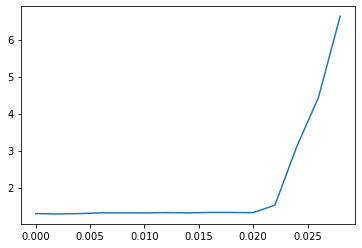

In [3]:
#original code to test pth
power_output_list =[]
power_list = np.arange(0,30,2)/1000

for x in power_list:
    print('Power is :',x*1000)
    laser.set(x)
    power_reading = []
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
    power_output_list.append(np.mean(np.array(power_reading)))


print(power_list)
print(power_output_list)
laser.set(0)
import matplotlib.pyplot as plt
plt.plot(power_list, power_output_list)

In [3]:
power_output_list = []
power_output_list_y = []
#get list of power around power threshhold
def getpowerarray(pth):
    powerarray1 = [0,0.3*pth,0.7*pth]
    powerarray2 = np.linspace(0.9*pth,1.3*pth,31)
    powerarray3 = [1.4*pth,1.5*pth,1.8*pth]

    powerarray = np.concatenate((powerarray1,powerarray2,powerarray3))/1000
    return powerarray

power_list = getpowerarray(18) #W

#taking power from both beam path simultaneously
for x in power_list:
    print('Power is :',x*1000, 'mW')
    laser.set(x)
    power_reading = []
    power_reading_y = []
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
        power_output_list.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6*powermeter2.take_power_reading())
    power_output_list_y.append(np.mean(np.array(power_reading_y)))

print(power_list)
print(power_output_list)
print(power_output_list_y)
laser.set(0)
import matplotlib.pyplot as plt
plt.plot(power_list, power_output_list)
plt.plot(power_list, power_output_list_y)

Power is : 0.0 mW


NameError: name 'powermeter' is not defined

Power is : 0.0
Power is : 6.3
Power is : 14.7
Power is : 18.900000000000002
Power is : 19.32
Power is : 19.740000000000002
Power is : 20.160000000000004
Power is : 20.580000000000002
Power is : 21.0
Power is : 21.42
Power is : 21.840000000000003
Power is : 22.26
Power is : 22.68
Power is : 23.1
Power is : 25.2
Power is : 31.5
Power is : 37.800000000000004
[0.      0.0063  0.0147  0.0189  0.01932 0.01974 0.02016 0.02058 0.021
 0.02142 0.02184 0.02226 0.02268 0.0231  0.0252  0.0315  0.0378 ]
[0.009333838832299999, 0.0099916576987, 0.010636774387100001, 0.011418074039999998, 0.012001551084000002, 0.012583727175, 0.012474011176000001, 0.015821591531, 0.46724768681999995, 0.6670381782600001, 0.16313140908000004, 0.20338498329999996, 0.22524900006999998, 0.24523994172000002, 0.39013391388999996, 1.0185525842, 3.1138151029]


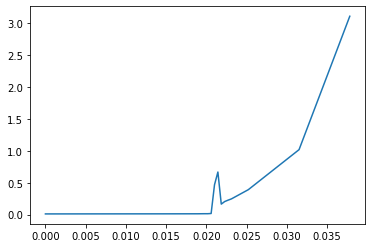

In [5]:
power_list = getpowerarray(21) #W
for x in power_list:
    print('Power is :',x*1000)
    laser.set(x)
    power_reading = []
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
    power_output_list.append(np.mean(np.array(power_reading)))

print(power_list)
print(power_output_list)
laser.set(0)
import matplotlib.pyplot as plt
plt.plot(power_list, power_output_list)

In [15]:
#constant power long time polarization measurmenet

timelist = np.linspace(0,1000,1001)
power_output_list_time = []

laser.set(0.023)


for x in timelist:
    print('time is:',x)
    power_reading = []
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
    power_output_list_time.append(np.mean(np.array(power_reading)))


print(timelist)
print(power_output_list_time)
laser.set(0)

plt.plot(timelist, power_output_list_time)



time is: 0.0
time is: 1.0
time is: 2.0
time is: 3.0
time is: 4.0
time is: 5.0
time is: 6.0
time is: 7.0
time is: 8.0
time is: 9.0
time is: 10.0
time is: 11.0
time is: 12.0
time is: 13.0
time is: 14.0
time is: 15.0
time is: 16.0
time is: 17.0
time is: 18.0
time is: 19.0
time is: 20.0
time is: 21.0
time is: 22.0
time is: 23.0
time is: 24.0
time is: 25.0
time is: 26.0
time is: 27.0
time is: 28.0
time is: 29.0
time is: 30.0
time is: 31.0
time is: 32.0
time is: 33.0
time is: 34.0
time is: 35.0
time is: 36.0
time is: 37.0
time is: 38.0
time is: 39.0
time is: 40.0
time is: 41.0
time is: 42.0
time is: 43.0
time is: 44.0
time is: 45.0
time is: 46.0
time is: 47.0
time is: 48.0
time is: 49.0
time is: 50.0
time is: 51.0
time is: 52.0
time is: 53.0
time is: 54.0
time is: 55.0
time is: 56.0
time is: 57.0
time is: 58.0
time is: 59.0
time is: 60.0
time is: 61.0
time is: 62.0
time is: 63.0
time is: 64.0
time is: 65.0
time is: 66.0
time is: 67.0
time is: 68.0
time is: 69.0
time is: 70.0
time is: 71.0
ti

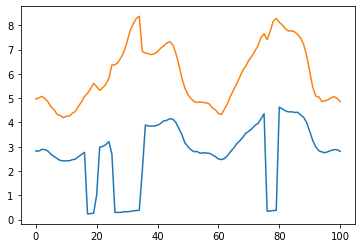

In [7]:
laser.set(0.032)

testtime = np.linspace(0,100,101)
power_output_list_testtime = []
power_output_list_testtime_y = []

for x in testtime:
    power_reading = []
    power_reading_y = []
    print('time is:',x)
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
        power_output_list_testtime.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6*powermeter2.take_power_reading())
        power_output_list_testtime_y.append(np.mean(np.array(power_reading_y)))
    #time.sleep(1)

plt.plot(testtime, power_output_list_testtime)
plt.plot(testtime,power_output_list_testtime_y)
print(power_output_list_testtime)
print(power_output_list_testtime_y)
print(testtime)

laser.set(0)


(0.0, 3.0)

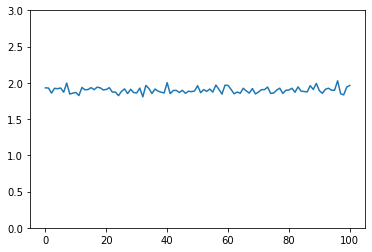

In [17]:
powerscale = np.linspace(0,1,101)
for x in range (101):
    powerscale[x] = power_output_list_testtime_y[x]/power_output_list_testtime[x]

plt.plot(testtime,powerscale)
plt.ylim(0,3)


In [5]:
laser.set(0.035)

Power is : 0.0 mW
Power is : 4.75 mW
Power is : 9.5 mW
Power is : 14.249999999999998 mW
Power is : 19.0 mW
Power is : 19.0 mW
Power is : 19.102040816326532 mW
Power is : 19.20408163265306 mW
Power is : 19.306122448979593 mW
Power is : 19.408163265306122 mW
Power is : 19.51020408163265 mW
Power is : 19.612244897959183 mW
Power is : 19.714285714285715 mW
Power is : 19.816326530612244 mW
Power is : 19.918367346938776 mW
Power is : 20.02040816326531 mW
Power is : 20.122448979591837 mW
Power is : 20.224489795918366 mW
Power is : 20.326530612244895 mW
Power is : 20.428571428571427 mW
Power is : 20.53061224489796 mW
Power is : 20.632653061224488 mW
Power is : 20.73469387755102 mW
Power is : 20.836734693877553 mW
Power is : 20.93877551020408 mW
Power is : 21.040816326530614 mW
Power is : 21.142857142857142 mW
Power is : 21.24489795918367 mW
Power is : 21.346938775510203 mW
Power is : 21.448979591836736 mW
Power is : 21.551020408163264 mW
Power is : 21.653061224489797 mW
Power is : 21.755102040

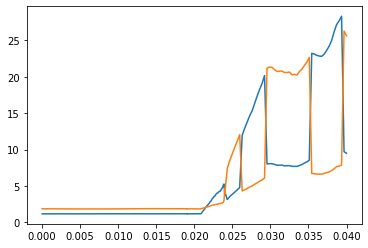

In [4]:
power_output_list = []
power_output_list_y = []
#get list of power around power threshhold


power_list1 = np.linspace(0, 0.019, 5)
power_list2 = np.linspace(0.019,0.024, 50)
power_list3 = np.linspace(0.024,0.040, 50)
power_list = np.concatenate((power_list1,power_list2,power_list3))
#taking power from both beam path simultaneously
for x in power_list:
    print('Power is :',x*1000, 'mW')
    laser.set(x)
    power_reading = []
    power_reading_y = []
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
        power_output_list.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6*powermeter2.take_power_reading())
    power_output_list_y.append(np.mean(np.array(power_reading_y)))

print(power_list)
print(power_output_list)
print(power_output_list_y)
laser.set(0)
import matplotlib.pyplot as plt
plt.plot(power_list, power_output_list)
plt.plot(power_list, power_output_list_y)

In [ ]:
power_output_list = []
power_output_list_y = []
#get list of power around power threshhold



power_list = np.linspace(0.028,0.028,200)
#taking power from both beam path simultaneously
for x in power_list:
    print('Power is :',x*1000, 'mW')
    laser.set(x)
    power_reading = []
    power_reading_y = []
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
        power_output_list.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6*powermeter2.take_power_reading())
    power_output_list_y.append(np.mean(np.array(power_reading_y)))

print(power_list)
print(power_output_list)
print(power_output_list_y)
laser.set(0)
import matplotlib.pyplot as plt
plt.plot(power_list, power_output_list)
plt.plot(power_list, power_output_list_y)

In [2]:
power_list = getpowerarray(53) #W
for x in power_list:
    print('Power is :',x*1000)
    laser.set(x)
    power_reading = []
    for k in range(1):
        power_reading.append(10**6*powermeter2.take_power_reading())
    power_output_list.append(np.mean(np.array(power_reading)))

print(power_list)
print(power_output_list)
laser.set(0)
import matplotlib.pyplot as plt
plt.plot(power_list, power_output_list)

NameError: name 'getpowerarray' is not defined